## This code performs the modeling and PI control analysis of the bicycle velocity using experimental data. The simulated responses are compared with measured data, and the results are visualized through plots exported as PDF figures.

In [4]:
# =========================
# Library imports
# =========================

import numpy as np # Numerical operations and matrix manipulation
import control as ctrl # Control systems library
import matplotlib.pyplot as plt # Plotting and visualization library


# =========================
# Figure formatting setup
# =========================

# Configures default plot appearance
plt.rcParams.update({

    # Uses serif fonts in all figures
    "font.family": "serif",

    # Sets Times New Roman as the main font
    "font.serif": ["Times New Roman"],

    # Uses STIX fonts for mathematical expressions
    "mathtext.fontset": "stix",

    # Ensures editable text in exported PDF files
    "pdf.fonttype": 42
})

### Loads the experimental data, simulates the first-order model response, and compares the simulated and measured velocities through plots.

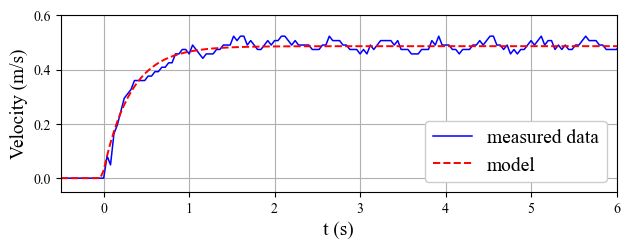

In [7]:
import numpy as np
import control as ctrl
import matplotlib.pyplot as plt


# =========================
# Experimental data
# =========================

data = np.loadtxt('motorStep.txt')

inicio = 2
final = 350

dados = data[inicio-1:final, :]

wheel_speed = dados[:, 0]
entrada     = dados[:, 1]
tempo       = dados[:, 2] - 9.13


# =========================
# First-order model
# =========================

k   = 0.18
tau = 0.32

M = ctrl.tf([k], [tau, 1])

resp = ctrl.forced_response(M, T=tempo, U=entrada)
y = np.squeeze(resp.outputs)


# =========================
# Figure
# =========================

# Recreates the original layout to preserve the upper plot dimensions
fig, (ax, ax_layout) = plt.subplots(2, 1)

ax.plot(tempo, wheel_speed, '-b', linewidth=1.1)
ax.plot(tempo, y, '--r', linewidth=1.4)

ax.set_ylabel('Velocity (m/s)', fontsize=14)

ax.legend(
    ['measured data', 'model'],
    loc='lower right',
    fontsize=14,
    framealpha=1.0
)

ax.grid(True, alpha=1.0)
ax.set_xlim([-0.5, 6])
ax.set_ylim([-0.05, 0.6])

# Temporary lower plot, used only to calculate the original layout
ax_layout.plot(tempo, entrada, 'b', linewidth=1.1)
ax_layout.set_xlabel('t (s)', fontsize=14)
ax_layout.set_ylabel('Voltage (V)', fontsize=14)
ax_layout.grid(True, alpha=1.0)
ax_layout.set_xlim([-0.5, 6])
ax_layout.set_ylim([-0.2, 3])

fig.tight_layout()
fig.canvas.draw()

# Stores the original drawing-area dimensions in inches
plot_box = (
    ax.get_window_extent()
    .transformed(fig.dpi_scale_trans.inverted())
    .frozen()
)

# Removes the lower plot and adds the time label to the remaining plot
ax_layout.remove()
ax.set_xlabel('t (s)', fontsize=14)

fig.canvas.draw()

# Determines the space required for the plot and its labels
crop_box = (
    ax.get_tightbbox(fig.canvas.get_renderer())
    .transformed(fig.dpi_scale_trans.inverted())
    .padded(0.1)
)

# Crops the figure without changing the drawing-area dimensions
fig.set_size_inches(crop_box.width, crop_box.height)

ax.set_position([
    (plot_box.x0 - crop_box.x0) / crop_box.width,
    (plot_box.y0 - crop_box.y0) / crop_box.height,
    plot_box.width / crop_box.width,
    plot_box.height / crop_box.height
])

# Do not call tight_layout() again after resizing
fig.savefig(
    'modelo_vel.pdf',
    format='pdf',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

### Loads the experimental control data, simulates the closed-loop PI controller response, and compares the simulated and measured velocities through plots.

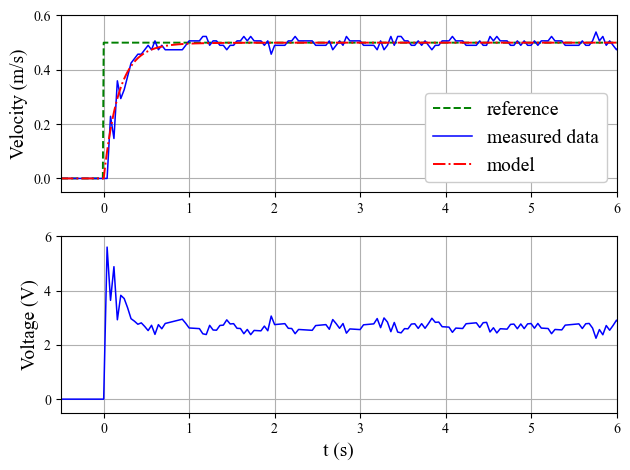

In [6]:
# =========================
# Experimental data
# =========================

# Loads experimental data file
data = np.loadtxt('motorControl.txt')

# Data interval used in the analysis
final = 360
inicio = 100

# Extracts selected data segment
dados = data[inicio-1:final, :]


# Experimental signals
wheel_speed = dados[:, 0]
entrada     = dados[:, 1]
tempo       = dados[:, 2] - 9.09


# =========================
# Plant model + PI controller
# =========================

k   = 0.18   # System gain
tau = 0.32   # Time constant (s)

# First-order plant model
M = ctrl.tf([k], [tau, 1])


# PI controller gains
kp = 10
ki = 30

# PI controller transfer function:
# C(s) = kp + ki/s
C = ctrl.tf([kp, ki], [1, 0])


# Closed-loop transfer function
F = ctrl.feedback(C * M, 1)


# Step response with amplitude 0.5
resp_t, y = ctrl.step_response(0.5 * F,
                               T=np.linspace(0, 10, 1000))


t = np.concatenate((np.array([-3.0, -0.01]), resp_t))
y = np.concatenate((np.array([0.0, 0.0]), y))


# Reference signal
r = np.zeros_like(t)
r[t >= 0] = 0.5


# =========================
# Figure
# =========================
plt.figure()


# Velocity comparison
plt.subplot(2, 1, 1)

plt.plot(t, r, '--g', linewidth=1.4)
plt.plot(tempo, wheel_speed, '-b', linewidth=1.1)
plt.plot(t, y, '-.r', linewidth=1.4)

plt.ylabel('Velocity (m/s)', fontsize=14)

plt.legend(['reference', 'measured data', 'model'],
           loc='lower right',
           fontsize=14,
           framealpha=1.0)

plt.xlim([-0.5, 6])
plt.ylim([-0.05, 0.6])

plt.grid(True, alpha=1.0)


# Control signal
plt.subplot(2, 1, 2)

plt.plot(tempo, entrada, 'b', linewidth=1.1)

plt.grid(True, alpha=1.0)

plt.xlabel('t (s)', fontsize=14)
plt.ylabel('Voltage (V)', fontsize=14)

plt.xlim([-0.5, 6])
plt.ylim([-0.5, 6])


# Adjusts subplot spacing
plt.tight_layout()


# Saves figure
plt.savefig('controle_vel.pdf',
            format='pdf',
            bbox_inches='tight',
            facecolor='white')


# Displays figure
plt.show()